In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    log_loss,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
)
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline  # Pipeline estándar
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

# Enrutamiento de metadatos: lleva `groups` hasta el CV interno
# del selector de variables
sklearn.set_config(enable_metadata_routing=True)

sys.path.insert(0, str(Path.cwd().parent))

from config import config
from utils.evaluador_cv import EvaluadorCV


def cox_snell_r2(model, X, y):
    """
    Calcula el R² de Cox & Snell para Regresión Logística.
    Requires probabilidades predichas del modelo.
    """
    n = len(y)
    # Log-likelihood del modelo actual
    probs = model.predict_proba(X)
    ll_model = -log_loss(y, probs, normalize=False)

    # Log-likelihood del modelo nulo (solo intercepto)
    p_null = np.mean(y)
    ll_null = np.sum(y * np.log(p_null) + (1 - y) * np.log(1 - p_null))

    return 1 - np.exp((2 / n) * (ll_null - ll_model))


def nagelkerke_r2(model, X, y):
    """
    Calcula el R² de Nagelkerke ajustando la escala entre 0 y 1.
    """
    n = len(y)
    p_null = np.mean(y)
    ll_null = np.sum(y * np.log(p_null) + (1 - y) * np.log(1 - p_null))

    cs_r2 = cox_snell_r2(model, X, y)
    max_r2 = 1 - np.exp((2 / n) * ll_null)

    return cs_r2 / max_r2


DIR_SPLITS = config.DATADIR / "splits"

# test.pkl no se abre hasta la evaluación final del proyecto
df_train = pd.read_pickle(DIR_SPLITS / "train.pkl")
df_val = pd.read_pickle(DIR_SPLITS / "val.pkl")
assert list(df_train.columns) == list(df_val.columns)

# Papel de cada columna (ver la conclusión de eda_consolidate.ipynb)
LLAVES = ["DIRECTORIO", "SECUENCIA_P"]  # trazabilidad, nunca entran a X
GRUPO = "SEGMENTO"  # grupos para StratifiedGroupKFold
PESO = "PESO"  # solo si se pondera el modelo
OBJETIVO = "POBRE"
CARACTERISTICAS = [
    c for c in df_train.columns if c not in [*LLAVES, GRUPO, PESO, OBJETIVO]
]

RANDOM_STATE = 42

# Cargar datos

In [2]:
X_train, y_train = df_train[CARACTERISTICAS], df_train[OBJETIVO]
grupos_train = df_train[GRUPO]
X_val, y_val = df_val[CARACTERISTICAS], df_val[OBJETIVO]

pd.DataFrame(
    {
        "hogares": [len(df_train), len(df_val)],
        "tasa POBRE": [y_train.mean(), y_val.mean()],
    },
    index=["train", "val"],
)

,hogares,tasa POBRE
train,31039,0.128419
val,6643,0.128707


# Generar funciones de evaluacion custom

In [3]:
UMBRAL = 0.5  # umbral de decisión para las métricas que lo necesitan


def custom_accuracy(y_true, y_proba, threshold):
    return accuracy_score(y_true, y_proba >= threshold)


def custom_precision(y_true, y_proba, threshold):
    return precision_score(y_true, y_proba >= threshold, zero_division=0)


def custom_recall(y_true, y_proba, threshold):
    return recall_score(y_true, y_proba >= threshold, zero_division=0)


def custom_kappa(y_true, y_proba, threshold):
    return cohen_kappa_score(y_true, y_proba >= threshold)


def crear_scoring(umbral):
    """Scorers con el umbral explícito.

    Para evaluar con otro umbral basta con volver a llamar la función:
    el umbral no queda congelado al definir las funciones.
    """

    def con_umbral(funcion):
        return make_scorer(
            funcion, response_method="predict_proba", threshold=umbral
        )

    return {
        "accuracy": con_umbral(custom_accuracy),
        "precision": con_umbral(custom_precision),
        "recall": con_umbral(custom_recall),
        "kappa": con_umbral(custom_kappa),
        # No depende del umbral: AP evalúa todos los umbrales
        "average_precision": "average_precision",
    }

# Modelo linea base

Se utiliza como linea base un predictor trivial de la moda, esto se utilizara como punto de partida para establecer que es lo que deben mejorar los modelos posteriores.


In [4]:
dummy_clas = DummyClassifier(strategy="most_frequent")

dummy_model_pipeline = Pipeline([("model", dummy_clas)])

sgkf = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

scores = cross_validate(
    estimator=dummy_model_pipeline,
    X=X_train,
    y=y_train,
    params={"groups": grupos_train},
    cv=sgkf,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "average_precision",
    ],  # average_precision es una aproximacion de PR-AUC
)

d:\Externado\Cuarto semestre\Machine Learning\Poverty_in_colombia\Multidimesional_poverty_in_Colombia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Externado\Cuarto semestre\Machine Learning\Poverty_in_colombia\Multidimesional_poverty_in_Colombia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Externado\Cuarto semestre\Machine Learning\Poverty_in_colombia\Multidimesional_poverty_in_Colombia\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision i

In [5]:
for metric, val in scores.items():
    print(f"{metric}: {val.mean()}")

fit_time: 0.043538236618041994
score_time: 0.015646934509277344
test_accuracy: 0.8715804473532263
test_precision: 0.0
test_recall: 0.0
test_average_precision: 0.12841955264677368


Matriz de confusión:
 [[27053     0]
 [ 3986     0]]


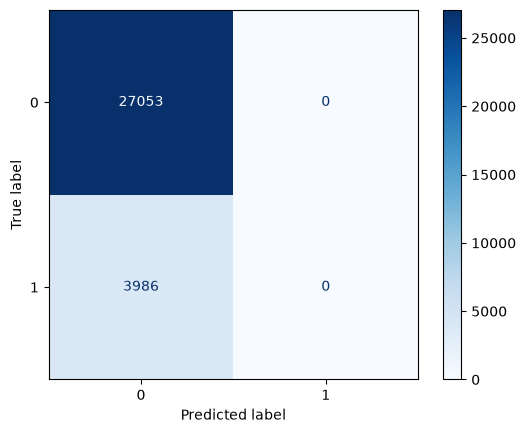

In [6]:
y_pred_dummy = cross_val_predict(
    estimator=dummy_model_pipeline,
    X=X_train,
    y=y_train,
    params={"groups": grupos_train},
    cv=sgkf,
)

# 2. Generar la matriz en texto/array
cm = confusion_matrix(y_train, y_pred_dummy)
print("Matriz de confusión:\n", cm)

# 3. Graficar la matriz de forma visual
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

Note que el modelo dummy da un accuracy promedio entre folds realmente alto (0.87), sin embargo esto es un artefacto del desbalance de clases, pues su recall es 0 y su precision da error matematico pero la libreria la vuelve 0, dicho esto lo que debera buscar en modelos posteriores es obtener un mayor recall ya que es mas critico detectar personas pobres, esto con el fin de evitar la omision de personas vulnerables, esto sin sacrificar en gran medida la precision para no clacificar mal sistematicamente. Esto se puede lograr sacrificando ese accuracy tan alto y se puede controlar su equilibrio utilizando la curva PR y PR-AUC o `average_precision` (no la ROC ya que el problema es desbalanceado).

# Primera propuesta de pipeline: Regresion Logistica usando pesos para lidear con el desbalance

A continuacion se presenta la primera propuesta de modelación, una regresion logistica, donde el primer paso consta de inputar los faltantes con el metodo propuesto en el cuaderno anterior, para posteriormente seleccionar 6 variables usando un metodo de seleccion secuiencia y por ultimo entrenar la regresion utilizando una funcion de coste pesada (rebalanceo por pesos).

Se omiten pasos como el escalamiento ya que las variables o son proporciones entre 0 y 1 o ya son variables codificadas segun el contexto, como se reporto en el notebook anterior (una de hecho ya venia codificada en la base original del DANE). 

El equipo considera util justificar la razon de que la primera propuesta utilice por metodo de balanceo el peso por clases, ya que no era muy usual en modelos anteriores del curso (especialmente en KNN), no obstante en un modelo como regresion lineal suele ser extremadamente util, pues los pesos funcionan como una suerte de "engaño" a la funcion de coste que eventualmente hace que el gradiente converga a un punto donde el modelo aprendio a minimizar el error con la miniria (pues a esta se le establece un mayor coste), de ahi que los pesos sean utiles en modelos ajustados mediante la otimizacion de alguna funcion de coste, por lo tanto la estructura de la pipeline es asi:

- Inputacion
- Seleccion de 6 caracteristicas
- Regresion Logistica Ponderada

## Crear Pipeline

In [7]:
model_log_reg_1 = LogisticRegression(class_weight="balanced", max_iter=1000)

sgkf = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

weighted_log_reg = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=model_log_reg_1,
                n_features_to_select=6,
                direction="backward",
                scoring="average_precision",  # Evalúa la selección con PR-AUC
                cv=sgkf,
                n_jobs=-1,  # Acelera la selección en paralelo
            ),
        ),
        ("model", model_log_reg_1),
    ]
)

## Evaluar con CV

In [8]:
print(f"umbral: {UMBRAL}")
scores = cross_validate(
    estimator=weighted_log_reg,
    X=X_train,
    y=y_train,
    params={"groups": grupos_train},
    cv=sgkf,
    scoring=crear_scoring(UMBRAL),
    return_estimator=True,
    return_indices=True,
)

umbral: 0.5


In [9]:
for metric, val in scores.items():
    # 'estimator' e 'indices' no son métricas
    if metric not in ("estimator", "indices"):
        print(f"{metric}: {np.mean(val):.3f} ± {np.std(val):.3f}")

fit_time: 25.968 ± 5.367
score_time: 0.027 ± 0.008
test_accuracy: 0.763 ± 0.004
test_precision: 0.245 ± 0.008
test_recall: 0.406 ± 0.018
test_kappa: 0.173 ± 0.013
test_average_precision: 0.257 ± 0.012


In [10]:
feature_counts = Counter()

for estimator in scores["estimator"]:
    # Nombres de variables después del imputer
    feat_names = estimator.named_steps["imputer"].get_feature_names_out(
        X_train.columns
    )

    # Máscara de las variables seleccionadas en este fold
    mask = estimator.named_steps["select_vars"].get_support()

    # Acumular las variables seleccionadas
    selected_in_fold = feat_names[mask]
    feature_counts.update(selected_in_fold)

# 2. Convertir a DataFrame para presentar los resultados organizados
n_folds = len(scores["estimator"])
df_frequencies = (
    pd.DataFrame(feature_counts.items(), columns=["Variable", "Frecuencia"])
    .sort_values(by="Frecuencia", ascending=False)
    .reset_index(drop=True)
)

# Agregar la proporción/porcentaje de selección
df_frequencies["Porcentaje"] = (df_frequencies["Frecuencia"] / n_folds) * 100

print(f"--- Frecuencia de selección de variables ({n_folds} Folds) ---")
print(df_frequencies.to_string(index=False))

--- Frecuencia de selección de variables (5 Folds) ---
                             Variable  Frecuencia  Porcentaje
                    ORG_analfabetismo           5       100.0
                 ORG_trabajo_infantil           5       100.0
              ORG_fuente_agua_cocinar           5       100.0
                   ORG_alcantarillado           5       100.0
missingindicator_ORG_trabajo_infantil           5       100.0
               ORG_servicio_sanitario           3        60.0
                        ORG_acueducto           2        40.0


In [11]:
# Probabilidades de cada pliegue con los modelos que ya ajustó
# cross_validate: no se reentrena nada
probas_cv = [
    (
        y_train.iloc[idx_te],
        estimador.predict_proba(X_train.iloc[idx_te])[:, 1],
    )
    for estimador, idx_te in zip(
        scores["estimator"], scores["indices"]["test"]
    )
]

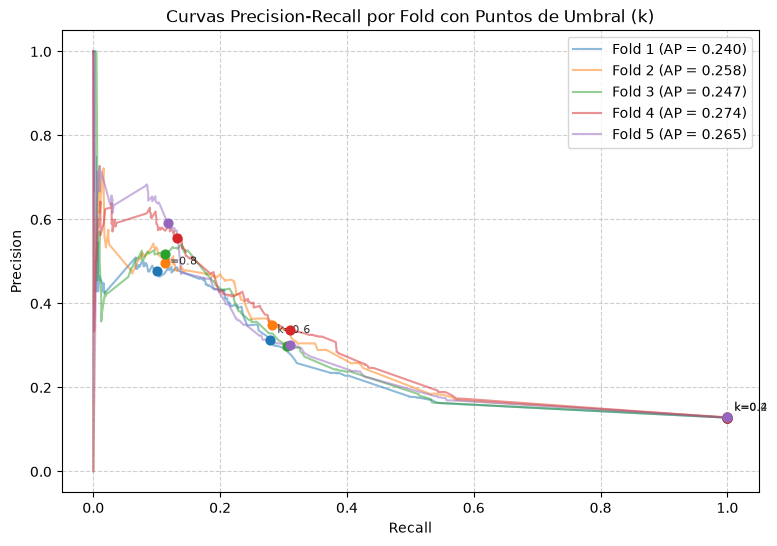

In [12]:
# Umbrales k (puntos de corte) que quieres visualizar en las curvas
thresholds_to_show = [0.2, 0.4, 0.6, 0.8]

fig, ax = plt.subplots(figsize=(9, 6))

# Probabilidades ya calculadas por pliegue (sin reentrenar)
for fold, (y_te, y_proba) in enumerate(probas_cv):
    # 1. Calcular precisión, recall y umbrales (thresholds)
    precision, recall, thresholds = precision_recall_curve(y_te, y_proba)
    ap = average_precision_score(y_te, y_proba)

    # 2. Graficar la curva PR del fold
    (line,) = ax.plot(
        recall, precision, alpha=0.5, label=f"Fold {fold + 1} (AP = {ap:.3f})"
    )
    fold_color = line.get_color()

    # 3. Marcar los umbrales k en la curva
    for k in thresholds_to_show:
        # Encontrar el índice del umbral más cercano a k
        idx = np.argmin(np.abs(thresholds - k))
        r_k, p_k = recall[idx], precision[idx]

        # Dibujar punto sobre la curva
        ax.scatter(r_k, p_k, color=fold_color, s=40, zorder=5)

        # Etiquetar el valor de k (solo en el Fold 1, para no saturar)
        if fold == 0:
            ax.annotate(
                f"k={k}",
                (r_k, p_k),
                textcoords="offset points",
                xytext=(5, 5),
                fontsize=8,
                alpha=0.8,
            )

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curvas Precision-Recall por Fold con Puntos de Umbral (k)")
ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()

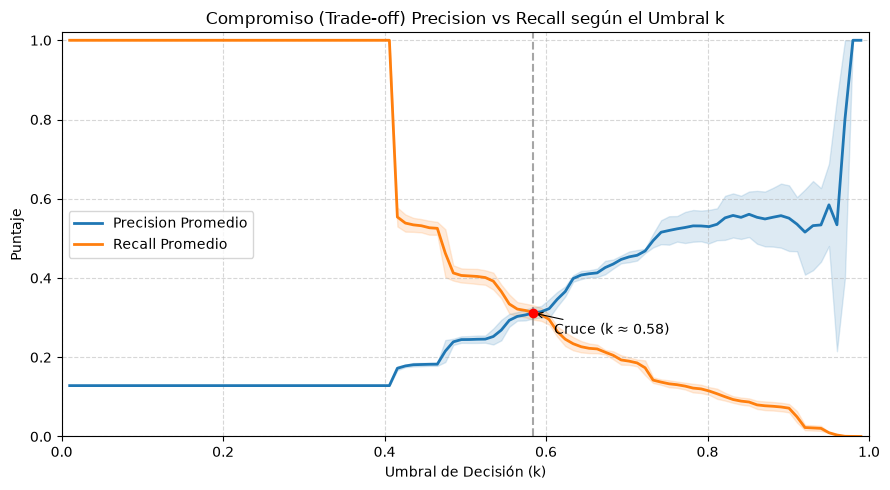

In [13]:
# 1. Definir una malla de umbrales k desde 0 hasta 1
k_thresholds = np.linspace(0.01, 0.99, 100)

# Listas para almacenar las métricas por fold
precisions_per_k = []
recalls_per_k = []

# 2. Iterar sobre las probabilidades de cada fold (sin reentrenar)
for y_te, y_proba in probas_cv:
    # Evaluar Precision y Recall para cada k en la malla
    fold_precisions = []
    fold_recalls = []

    for k in k_thresholds:
        y_pred_k = (y_proba >= k).astype(int)

        # Calcular métricas para el umbral k
        tp = np.sum((y_te == 1) & (y_pred_k == 1))
        fp = np.sum((y_te == 0) & (y_pred_k == 1))
        fn = np.sum((y_te == 1) & (y_pred_k == 0))

        prec = tp / (tp + fp) if (tp + fp) > 0 else 1.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0

        fold_precisions.append(prec)
        fold_recalls.append(rec)

    precisions_per_k.append(fold_precisions)
    recalls_per_k.append(fold_recalls)

# 3. Promediar el comportamiento a través de los folds
mean_precision = np.mean(precisions_per_k, axis=0)
std_precision = np.std(precisions_per_k, axis=0)

mean_recall = np.mean(recalls_per_k, axis=0)
std_recall = np.std(recalls_per_k, axis=0)

# 4. Graficar Precision y Recall vs Umbral k
fig, ax = plt.subplots(figsize=(9, 5))

# Curva de Precision
ax.plot(
    k_thresholds,
    mean_precision,
    label="Precision Promedio",
    color="#1f77b4",
    lw=2,
)
ax.fill_between(
    k_thresholds,
    np.clip(mean_precision - std_precision, 0, 1),
    np.clip(mean_precision + std_precision, 0, 1),
    color="#1f77b4",
    alpha=0.15,
)

# Curva de Recall
ax.plot(
    k_thresholds, mean_recall, label="Recall Promedio", color="#ff7f0e", lw=2
)
ax.fill_between(
    k_thresholds,
    np.clip(mean_recall - std_recall, 0, 1),
    np.clip(mean_recall + std_recall, 0, 1),
    color="#ff7f0e",
    alpha=0.15,
)

# Marcar el punto donde se intersectan (Trade-off equilibrado)
idx_intersection = np.argmin(np.abs(mean_precision - mean_recall))
k_intersect = k_thresholds[idx_intersection]
val_intersect = mean_precision[idx_intersection]

ax.axvline(x=k_intersect, color="grey", linestyle="--", alpha=0.7)
ax.scatter([k_intersect], [val_intersect], color="red", zorder=5)
ax.annotate(
    f"Cruce (k ≈ {k_intersect:.2f})",
    (k_intersect, val_intersect),
    xytext=(15, -15),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=0.8),
)

ax.set_xlabel("Umbral de Decisión (k)")
ax.set_ylabel("Puntaje")
ax.set_title("Compromiso (Trade-off) Precision vs Recall según el Umbral k")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()